# FactoryMind AI — Production Prediction Model
Trains and evaluates the production output regression model (XGBoost).

In [1]:
import sys
sys.path.insert(0, '../src')
from production_model import train
model, scaler, metrics = train()
metrics

Production model trained: {'mae': 15.69, 'rmse': 19.87, 'r2': 0.9774, 'model_type': 'XGBoost'}


{'mae': 15.69, 'rmse': 19.87, 'r2': 0.9774, 'model_type': 'XGBoost'}

## Actual vs Predicted (test set)

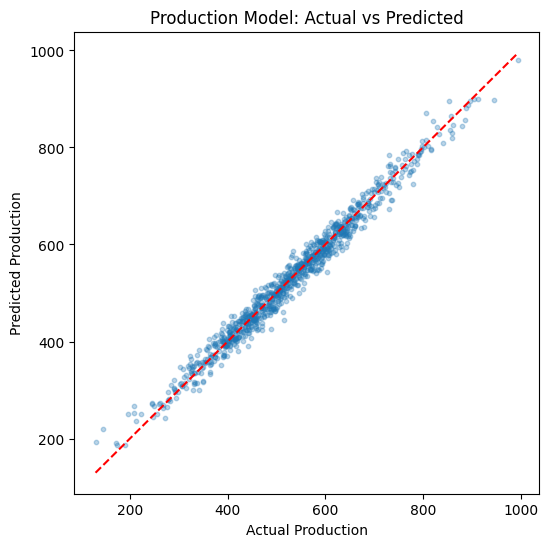

In [2]:
import pandas as pd, matplotlib.pyplot as plt
from preprocessing import PRODUCTION_FEATURES, load_machine_data
from sklearn.model_selection import train_test_split

df = load_machine_data('../data/machine_data.csv')
X = df[PRODUCTION_FEATURES]
y = df['Production_Output']
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_test_s = scaler.transform(X_test.values)
y_pred = model.predict(X_test_s)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Production'); plt.ylabel('Predicted Production')
plt.title('Production Model: Actual vs Predicted')
plt.show()

## Sample prediction with efficiency

In [3]:
from production_model import predict_production
sample_row = X_test.iloc[0].to_dict()
target = 1000 * sample_row['Production_Load']
predict_production(model, scaler, sample_row, target)

{'target_production': 609.0,
 'predicted_production': 462.6,
 'efficiency_pct': 76.0}